<a href="https://www.kaggle.com/code/fareedhassan/food-prices-forcasting-in-ng?scriptVersionId=368316140" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Forecasting Nigerian Food Prices
Seasonal naive vs SARIMA vs gradient boosting, judged with rolling-origin backtesting.

**Setup:** upload `food_prices_synthetic.csv` as a Kaggle dataset and add it as input. (Practice data. Later swap in the real WFP file; see the adapter cell.)

In [1]:
import glob, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import GradientBoostingRegressor
warnings.filterwarnings('ignore')
cands = glob.glob('/kaggle/input/**/*.csv', recursive=True) + glob.glob('*.csv')
print(cands)
path = next(f for f in cands if {'price_ngn_per_kg','price'} & set(pd.read_csv(f, nrows=1).columns))
raw = pd.read_csv(path, low_memory=False)
raw = raw[~raw.iloc[:,0].astype(str).str.startswith('#')]       # drop the HXL tag row in real WFP files
raw['date'] = pd.to_datetime(raw['date'])
if 'price_ngn_per_kg' in raw.columns:                            # synthetic practice file
    df = raw[['date','market','commodity','price_ngn_per_kg']].copy(); df['unit'] = 'KG'
else:                                                            # real WFP / HDX file
    raw['price'] = pd.to_numeric(raw['price'], errors='coerce')
    df = raw[raw.currency=='NGN'].rename(columns={'price':'price_ngn_per_kg'})[['date','market','commodity','unit','price_ngn_per_kg']]
df['month'] = df.date.dt.to_period('M').dt.to_timestamp()
df = df.groupby(['market','commodity','unit','month'], as_index=False).price_ngn_per_kg.mean().rename(columns={'month':'date'})
print(df.shape); print(df.unit.value_counts().head(8))

['/kaggle/input/datasets/fareedhassan/food-price/wfp_food_prices_nga.csv']
(90471, 5)
unit
100 KG    16422
KG        15239
2.5 KG     9583
L          8966
2.7 KG     5147
400 G      4617
2.1 KG     4361
0.5 KG     4278
Name: count, dtype: int64


### Print the dataset

In [2]:
# ---- PRINT THE DATASET ----
print('Raw file:', raw.shape, '| columns:', list(raw.columns))
display(raw.head(10))                                   # first rows exactly as downloaded
print('Monthly table used for modelling:', df.shape)
display(df.head(10))
print('Date range:', df.date.min().date(), 'to', df.date.max().date())
print('Markets:', df.market.nunique(), '| commodities:', df.commodity.nunique(), '| units:', df.unit.nunique())
display(df.describe(include='all').T)

Raw file: (90471, 16) | columns: ['date', 'admin1', 'admin2', 'market', 'market_id', 'latitude', 'longitude', 'category', 'commodity', 'commodity_id', 'unit', 'priceflag', 'pricetype', 'currency', 'price', 'usdprice']


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Maize,51,KG,actual,Wholesale,NGN,175.92,1.54
1,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Millet,73,KG,actual,Wholesale,NGN,150.18,1.31
2,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Rice (imported),64,KG,actual,Wholesale,NGN,358.70,3.14
3,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Sorghum,65,KG,actual,Wholesale,NGN,155.61,1.36
4,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,pulses and nuts,Beans (niebe),120,KG,actual,Wholesale,NGN,196.87,1.72
5,2002-01-15,Sokoto,Gada,Illela (CBM),1037,13.64,5.28,cereals and tubers,Maize,51,KG,actual,Wholesale,NGN,153.35,1.34
6,2002-01-15,Sokoto,Gada,Illela (CBM),1037,13.64,5.28,cereals and tubers,Millet,73,KG,actual,Wholesale,NGN,146.95,1.29
7,2002-01-15,Sokoto,Gada,Illela (CBM),1037,13.64,5.28,cereals and tubers,Rice (imported),64,KG,actual,Wholesale,NGN,337.59,2.95
8,2002-01-15,Sokoto,Gada,Illela (CBM),1037,13.64,5.28,cereals and tubers,Sorghum,65,KG,actual,Wholesale,NGN,141.50,1.24
9,2002-01-15,Sokoto,Gada,Illela (CBM),1037,13.64,5.28,pulses and nuts,Beans (niebe),120,KG,actual,Wholesale,NGN,239.07,2.09


Monthly table used for modelling: (90471, 5)


,market,commodity,unit,date,price_ngn_per_kg
0,Aba,Bread,Unit,2014-07-01,214.29
1,Aba,Bread,Unit,2014-08-01,230.91
2,Aba,Bread,Unit,2014-09-01,247.52
3,Aba,Bread,Unit,2014-10-01,247.52
4,Aba,Bread,Unit,2014-11-01,247.52
5,Aba,Bread,Unit,2014-12-01,247.52
6,Aba,Bread,Unit,2015-01-01,247.52
7,Aba,Bread,Unit,2015-02-01,247.52
8,Aba,Bread,Unit,2015-03-01,247.52
9,Aba,Bread,Unit,2015-04-01,247.52


Date range: 2002-01-01 to 2026-10-01
Markets: 68 | commodities: 43 | units: 20


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
market,90471,68,Potiskum,4102,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity,90471,43,Millet,5080,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit,90471,20,100 KG,16422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,90471,NaN,NaN,NaN,2020-09-24 21:01:40.155851264,2002-01-01 00:00:00,2018-06-01 00:00:00,2020-11-01 00:00:00,2023-07-01 00:00:00,2026-10-01 00:00:00,NaN
price_ngn_per_kg,90471.0,NaN,NaN,NaN,5034.334441,1.0,275.9,940.0,4000.0,138000.0,9994.234034


### Data coverage

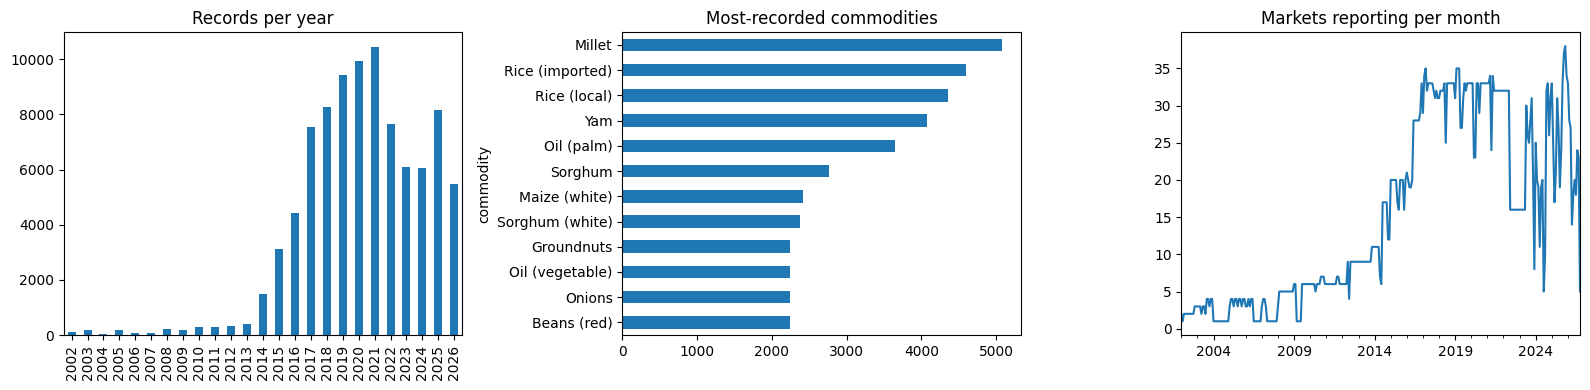

In [3]:
# ---- DATA COVERAGE ----
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby(df.date.dt.year).size().plot.bar(ax=ax[0]); ax[0].set_title('Records per year'); ax[0].set_xlabel('')
df.commodity.value_counts().head(12).sort_values().plot.barh(ax=ax[1]); ax[1].set_title('Most-recorded commodities')
df.groupby('date').market.nunique().plot(ax=ax[2]); ax[2].set_title('Markets reporting per month'); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()

## 1. Pick a series (market + commodity + unit) with long monthly history

Data runs to 2026-10-01
                                 count        min        max
market   commodity       unit                               
Potiskum Yam             2.5 KG    123 2015-01-01 2026-09-01
         Oil (palm)      L         118 2015-10-01 2026-09-01
         Rice (local)    2.7 KG    110 2016-12-01 2026-09-01
         Rice (imported) 2.8 KG    110 2016-12-01 2026-09-01
         Millet          2.6 KG    110 2016-12-01 2026-09-01
Monday   Maize flour     2.1 KG    106 2016-06-01 2026-09-01
         Fish            KG        106 2016-06-01 2026-09-01
         Groundnuts      2.2 KG    106 2016-06-01 2026-09-01
         Yam             2.5 KG    106 2016-06-01 2026-09-01
         Rice (local)    2.7 KG    106 2016-06-01 2026-09-01
         Oil (palm)      L         106 2016-06-01 2026-09-01
         Onions          0.5 KG    106 2016-06-01 2026-09-01
         Milk (powder)   400 G     106 2016-06-01 2026-09-01
         Beans (red)     2.5 KG    106 2016-06-01 2026-09-01


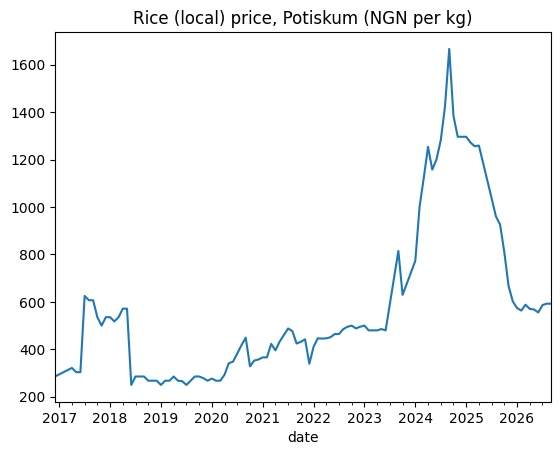

In [4]:
START = '2015-01-01'          # ignore very old data; change if you want a longer history
d = df[df.date >= START]
last_overall = d.date.max()
cov = (d.groupby(['market','commodity','unit']).date.agg(['count','min','max']).sort_values('count', ascending=False))
recent = cov[cov['max'] >= last_overall - pd.DateOffset(months=6)]     # must still be reporting recently
print('Data runs to', last_overall.date()); print(recent.head(15))
# Auto-pick the best-covered recent rice series. Change MARKET / COMMODITY / UNIT to choose another from the table above.
pick = recent[recent.index.get_level_values('commodity').str.contains('rice', case=False)].index[0]
MARKET, COMMODITY, UNIT = pick
print('Using:', pick)
s = d[(d.market==MARKET)&(d.commodity==COMMODITY)&(d.unit==UNIT)].set_index('date').price_ngn_per_kg
# convert the quoted pack price (e.g. NGN per 2.7 KG) to NGN per kg (or per litre for oils)
import re
def pack_size(unit):
    m = re.match(r'^\s*([\d.]+)?\s*(KG|G|L|ML)\s*$', str(unit).strip(), re.I)
    if not m: return None, str(unit)
    n = float(m.group(1) or 1); u = m.group(2).upper()
    return {'KG':(n,'kg'), 'G':(n/1000,'kg'), 'L':(n,'litre'), 'ML':(n/1000,'litre')}[u]
size, base = pack_size(UNIT)
if size:
    s = s / size; UNIT_LABEL = base
    print(f'Converted from NGN per {UNIT} to NGN per {base}  (divided by {size:g})')
else:
    UNIT_LABEL = UNIT; print('WARNING: unit', UNIT, 'not recognised, prices left as quoted')
series = s.asfreq('MS')
print('months:', len(series), '| missing before cleaning:', series.isna().sum())
# remove obvious recording errors: points far from the local median
med = series.rolling(7, center=True, min_periods=3).median()
bad = (series/med > 1.6) | (series/med < 0.6)
print('outliers removed:', int(bad.sum()))
series = series.mask(bad)
series = series.loc[series.first_valid_index():series.last_valid_index()]
n_filled = int(series.isna().sum())
series = series.interpolate(method='linear').asfreq('MS')
print('months filled by interpolation:', n_filled, 'of', len(series), '| any NaN left:', series.isna().any())
series.plot(title=f'{COMMODITY} price, {MARKET} (NGN per {UNIT_LABEL})'); plt.show()

### The series used, as a table

In [5]:
# ---- THE SERIES YOU MODEL, as a table ----
tbl = series.to_frame(f'price_ngn_per_{UNIT_LABEL}')
tbl['filled_or_cleaned'] = s.asfreq('MS').reindex(series.index).isna() | bad.reindex(series.index).fillna(False)
print(f'{COMMODITY}, {MARKET}: {len(tbl)} months, {int(tbl.filled_or_cleaned.sum())} filled/cleaned')
display(tbl.head(10)); display(tbl.tail(10))
tbl.to_csv('series_used.csv')                           # appears under /kaggle/working/ in the Output panel

Rice (local), Potiskum: 118 months, 8 filled/cleaned


,price_ngn_per_kg,filled_or_cleaned
date,,
2016-12-01,285.555556,False
2017-01-01,294.567901,True
2017-02-01,303.580247,True
2017-03-01,312.592593,False
2017-04-01,321.481481,False
2017-05-01,303.703704,False
2017-06-01,303.703704,False
2017-07-01,625.185185,False
2017-08-01,607.037037,False


,price_ngn_per_kg,filled_or_cleaned
date,,
2025-12-01,601.851852,False
2026-01-01,574.074074,False
2026-02-01,563.492593,False
2026-03-01,588.122222,False
2026-04-01,570.370370,False
2026-05-01,568.100000,False
2026-06-01,555.555556,False
2026-07-01,586.618519,False
2026-08-01,592.592593,False


### What cleaning did to the series

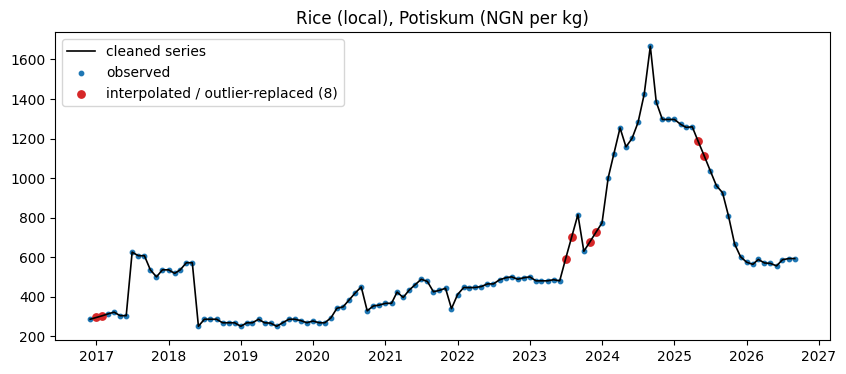

In [6]:
# ---- WHAT CLEANING DID TO YOUR SERIES ----
orig = s.asfreq('MS').reindex(series.index); filled = orig.isna() | bad.reindex(series.index).fillna(False)
plt.figure(figsize=(10, 4)); plt.plot(series.index, series, color='k', lw=1.2, label='cleaned series')
plt.scatter(orig.index[~filled], orig[~filled], s=10, color='C0', label='observed')
plt.scatter(series.index[filled], series[filled], s=28, color='C3', label=f'interpolated / outlier-replaced ({int(filled.sum())})')
plt.title(f'{COMMODITY}, {MARKET} (NGN per {UNIT_LABEL})'); plt.legend(); plt.show()

### Price index of other foods in the same market

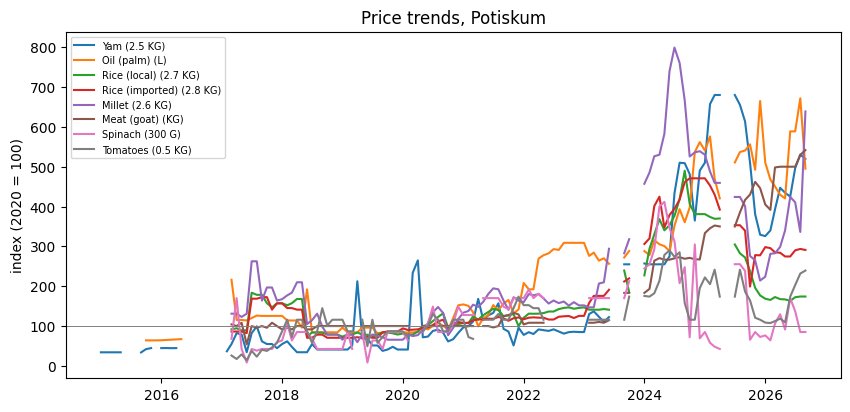

In [7]:
# ---- PRICE INDEX OF THE BEST-COVERED RECENT SERIES (2020 average = 100) ----
import re
def per_unit(u):
    m = re.match(r'^\s*([\d.]+)?\s*(KG|G|L|ML)\s*$', str(u).strip(), re.I)
    if not m: return None
    n = float(m.group(1) or 1); return n/1000 if m.group(2).upper() == 'G' else (n/1000 if m.group(2).upper() == 'ML' else n)
top = recent[recent.index.get_level_values('market') == MARKET].head(8)
plt.figure(figsize=(10, 4.5))
for (mk, cm, un), _ in top.iterrows():
    sz = per_unit(un)
    if not sz: continue
    z = d[(d.market==mk)&(d.commodity==cm)&(d.unit==un)].set_index('date').price_ngn_per_kg.asfreq('MS')
    base = z['2020'].mean()
    if np.isfinite(base) and base > 0: plt.plot(z.index, 100*z/base, label=f'{cm} ({un})')
plt.axhline(100, color='gray', lw=.7); plt.ylabel('index (2020 = 100)'); plt.title(f'Price trends, {MARKET}'); plt.legend(fontsize=7); plt.show()

### Inflation and seasonality

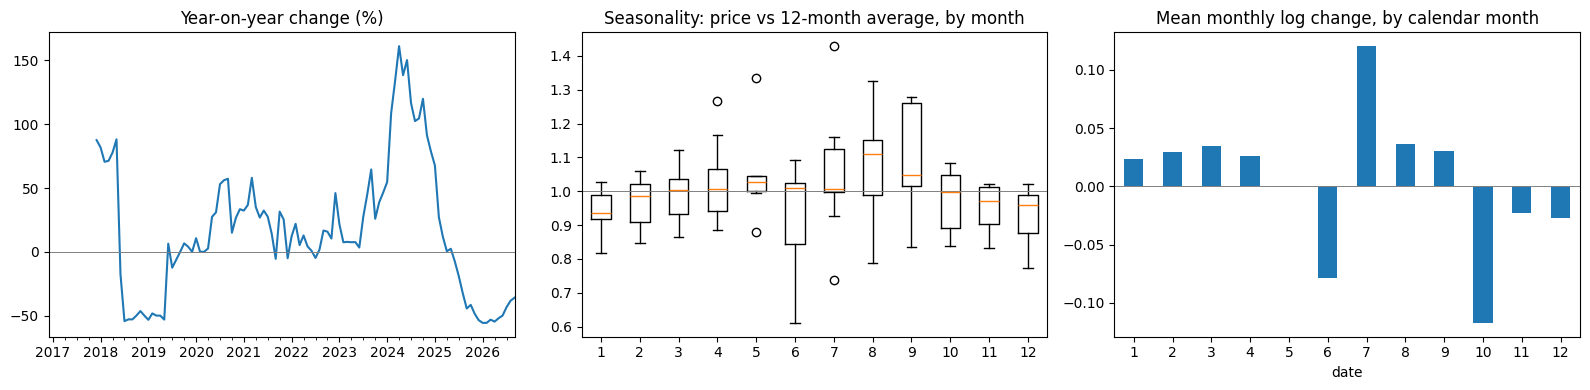

In [8]:
# ---- INFLATION AND SEASONALITY OF YOUR SERIES ----
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
(series.pct_change(12)*100).plot(ax=ax[0]); ax[0].axhline(0, color='gray', lw=.7); ax[0].set_title('Year-on-year change (%)'); ax[0].set_xlabel('')
dev = (series / series.rolling(12, center=True).mean()).dropna()          # remove the trend, keep the yearly pattern
dev.groupby(dev.index.month).apply(list).pipe(lambda g: ax[1].boxplot(list(g.values), tick_labels=list(g.index)))
ax[1].axhline(1, color='gray', lw=.7); ax[1].set_title('Seasonality: price vs 12-month average, by month')
lc = np.log(series).diff().dropna(); lc.groupby(lc.index.month).mean().plot.bar(ax=ax[2], rot=0); ax[2].axhline(0, color='gray', lw=.7)
ax[2].set_title('Mean monthly log change, by calendar month'); plt.tight_layout(); plt.show()

### Autocorrelation and decomposition

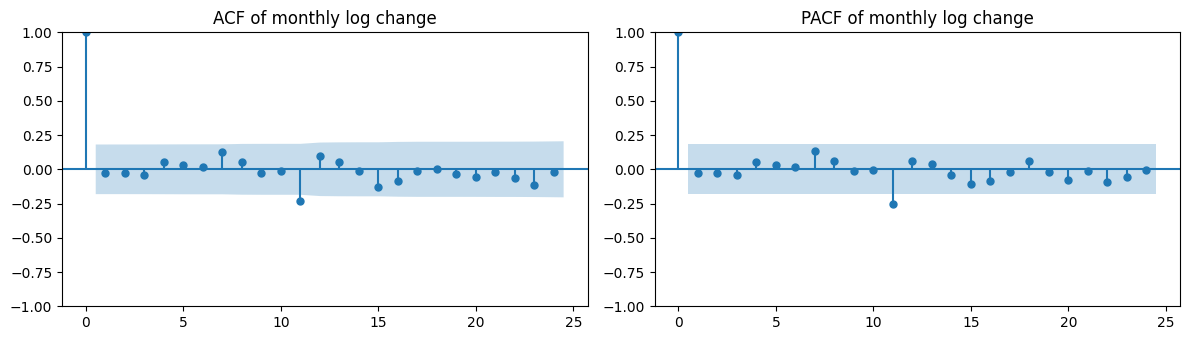

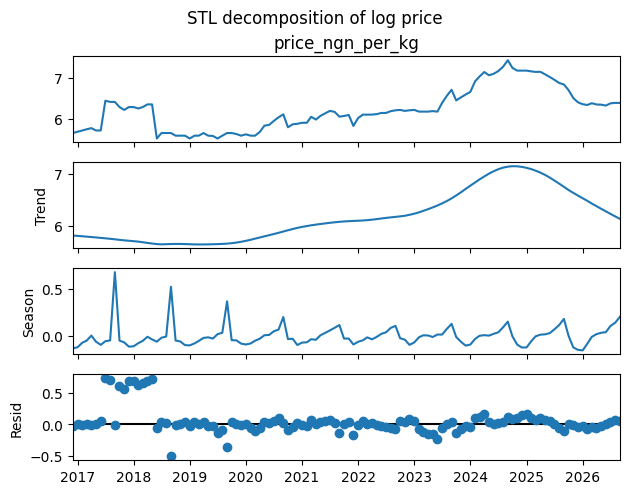

In [9]:
# ---- AUTOCORRELATION AND DECOMPOSITION ----
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
ld = np.log(series).diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5)); plot_acf(ld, lags=24, ax=ax[0], title='ACF of monthly log change'); plot_pacf(ld, lags=24, ax=ax[1], title='PACF of monthly log change'); plt.tight_layout(); plt.show()
STL(np.log(series), period=12, robust=True).fit().plot(); plt.suptitle('STL decomposition of log price', y=1.02); plt.show()

## 2. Models

In [10]:
def seasonal_naive(train, h): return np.array([train.iloc[-12 + (i % 12)] for i in range(h)])

def sarima(train, h):
    fit = SARIMAX(np.log(train.values), order=(1,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
    return np.exp(np.asarray(fit.forecast(h)))

def gboost(train, h):
    s = np.log(train); d = pd.DataFrame({'y': s})
    for l in (1,2,3,6,12): d[f'lag{l}'] = s.shift(l)
    d['m'] = d.index.month; d = d.dropna()
    X, y = d.drop(columns='y'), d.y
    m = GradientBoostingRegressor(random_state=42).fit(X, y)
    hist = list(s.values); idx = train.index[-1]; out = []
    for _ in range(h):
        idx = idx + pd.offsets.MonthBegin(1)
        row = {f'lag{l}': hist[-l] for l in (1,2,3,6,12)}; row['m'] = idx.month
        p = m.predict(pd.DataFrame([row]))[0]; hist.append(p); out.append(p)
    return np.exp(out)
def last_value(train, h): return np.repeat(train.iloc[-1], h)   # naive: next months = this month
models = {'last_value': last_value, 'seasonal_naive': seasonal_naive, 'sarima': sarima, 'gboost': gboost}

## 3. Rolling-origin backtest (12 folds, 6-month horizon)
Train only on the past at each step. MASE below 1 means better than the naive baseline.

In [11]:
H, FOLDS = 6, 12
scale = np.mean(np.abs(series.values[12:] - series.values[:-12]))   # seasonal naive in-sample error
rows = []
for k in range(FOLDS):
    cut = len(series) - H - (FOLDS-1-k)*3
    train, test = series.iloc[:cut], series.iloc[cut:cut+H]
    for n, f in models.items():
        p = f(train, H); e = test.values - p
        rows.append([n, k, test.index[0].strftime('%Y-%m'), np.mean(np.abs(e)), np.sqrt(np.mean(e**2)), np.mean(np.abs(e))/scale])
res = pd.DataFrame(rows, columns=['model','fold','test_start','MAE','RMSE','MASE'])
summary = res.groupby('model')[['MAE','RMSE','MASE']].mean().round(2).sort_values('MASE'); summary

,MAE,RMSE,MASE
model,,,
last_value,195.87,220.22,0.80
sarima,207.56,234.52,0.85
gboost,270.28,301.56,1.10
seasonal_naive,489.64,520.01,2.00


### Per-fold MAE (NGN)
Shows where each model's errors blow up. Each row is one backtest fold, labelled by the first month it forecasts.

In [12]:
per_fold = res.pivot_table(index=['fold','test_start'], columns='model', values='MAE').round(0)
per_fold['best'] = per_fold.idxmin(axis=1)
print('Folds won:'); print(per_fold['best'].value_counts())
per_fold

Folds won:
best
sarima        6
last_value    5
gboost        1
Name: count, dtype: int64


,model,gboost,last_value,sarima,seasonal_naive,best
fold,test_start,,,,,
0,2023-07,243.0,210.0,166.0,202.0,sarima
1,2023-10,260.0,158.0,134.0,331.0,sarima
2,2024-01,441.0,360.0,326.0,601.0,sarima
3,2024-04,370.0,207.0,111.0,738.0,sarima
4,2024-07,298.0,190.0,81.0,701.0,sarima
5,2024-10,175.0,366.0,276.0,479.0,gboost
6,2025-01,280.0,66.0,270.0,175.0,last_value
7,2025-04,242.0,177.0,311.0,262.0,last_value
8,2025-07,411.0,277.0,477.0,558.0,last_value


### Backtest results as pictures

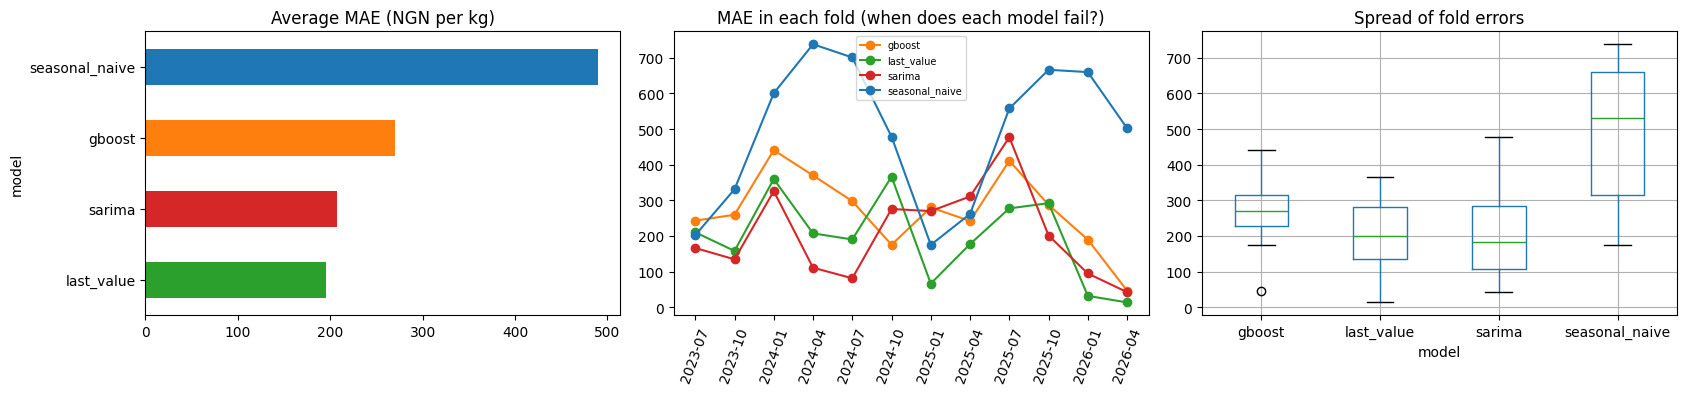

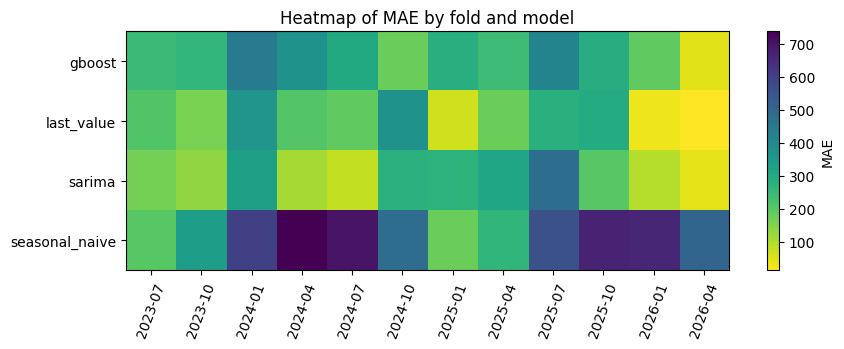

In [13]:
# ---- BACKTEST RESULTS AS PICTURES ----
colors = {'last_value': 'C2', 'sarima': 'C3', 'gboost': 'C1', 'seasonal_naive': 'C0'}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
summary['MAE'].sort_values().plot.barh(ax=ax[0], color=[colors[m] for m in summary['MAE'].sort_values().index]); ax[0].set_title('Average MAE (NGN per kg)')
pf = res.pivot_table(index='test_start', columns='model', values='MAE')
for m in pf: ax[1].plot(pf.index, pf[m], marker='o', color=colors[m], label=m)
ax[1].set_title('MAE in each fold (when does each model fail?)'); ax[1].tick_params(axis='x', rotation=70); ax[1].legend(fontsize=7)
res.boxplot(column='MAE', by='model', ax=ax[2]); ax[2].set_title('Spread of fold errors'); plt.suptitle(''); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(9, 3.6)); im = ax.imshow(pf.T.values, aspect='auto', cmap='viridis_r')
ax.set_xticks(range(len(pf.index))); ax.set_xticklabels(pf.index, rotation=70); ax.set_yticks(range(len(pf.columns))); ax.set_yticklabels(pf.columns)
plt.colorbar(im, label='MAE'); ax.set_title('Heatmap of MAE by fold and model'); plt.tight_layout(); plt.show()

## 4. Plot the last fold

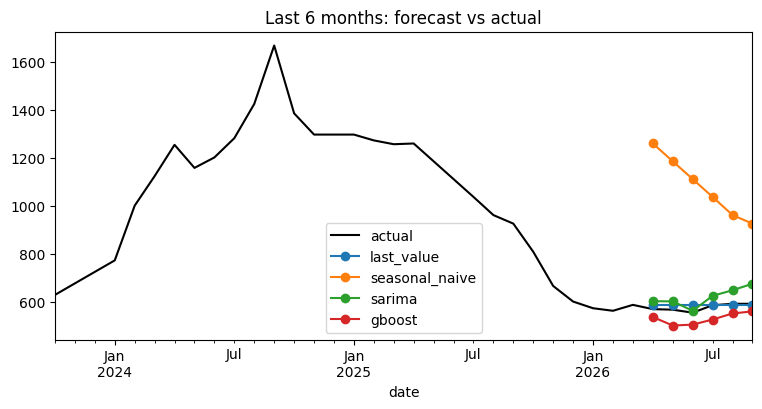

In [14]:
train, test = series.iloc[:-H], series.iloc[-H:]
ax = series[-36:].plot(label='actual', color='k', figsize=(9,4))
for n,f in models.items():
    pd.Series(f(train,H), index=test.index).plot(ax=ax, marker='o', label=n)   # plot via pandas so the date axis matches
ax.legend(); plt.title('Last 6 months: forecast vs actual'); plt.show()

### Forecasts vs actual in four folds

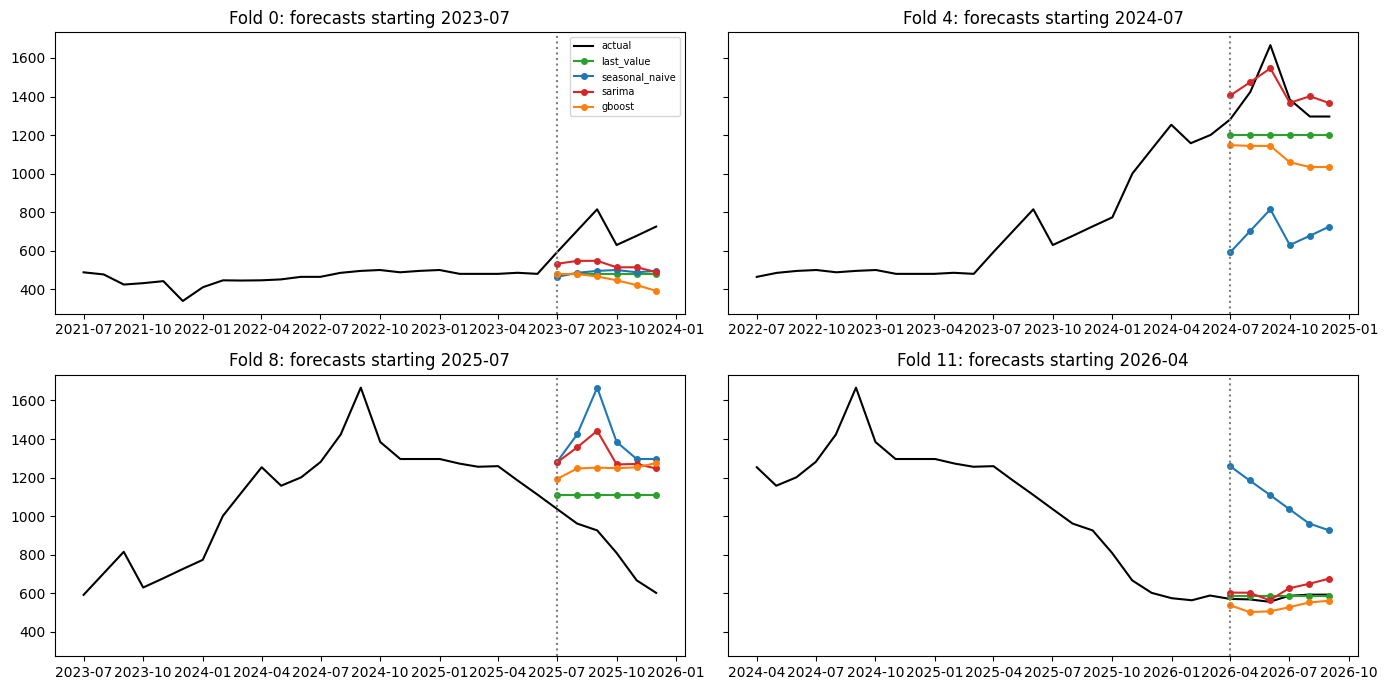

In [15]:
# ---- FORECASTS vs ACTUAL IN SEVERAL FOLDS ----
show = [0, 4, 8, 11]
fig, axs = plt.subplots(2, 2, figsize=(14, 7), sharey=True)
for ax, k in zip(axs.ravel(), show):
    cut = len(series) - H - (FOLDS-1-k)*3; tr, te = series.iloc[:cut], series.iloc[cut:cut+H]
    ax.plot(series.index[max(0, cut-24):cut+H], series.iloc[max(0, cut-24):cut+H], color='k', label='actual')
    for n, f in models.items(): ax.plot(te.index, f(tr, H), marker='o', ms=4, color=colors[n], label=n)
    ax.axvline(te.index[0], color='gray', ls=':'); ax.set_title(f'Fold {k}: forecasts starting {te.index[0]:%Y-%m}')
axs[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

### Error by forecast horizon

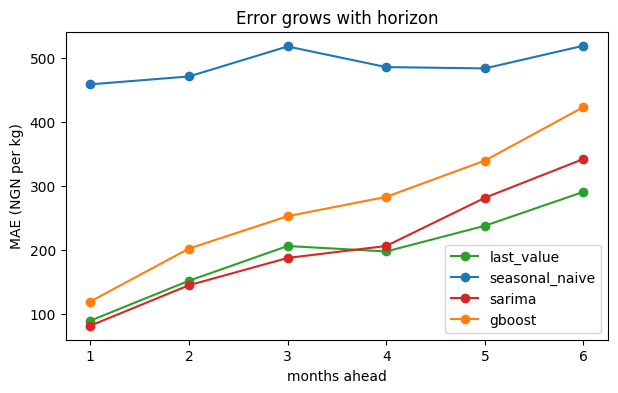

In [16]:
# ---- ERROR BY FORECAST HORIZON (1 to 6 months ahead) ----
err = {n: np.zeros((FOLDS, H)) for n in models}
for k in range(FOLDS):
    cut = len(series) - H - (FOLDS-1-k)*3; tr, te = series.iloc[:cut], series.iloc[cut:cut+H]
    for n, f in models.items(): err[n][k] = np.abs(te.values - f(tr, H))
plt.figure(figsize=(7, 4))
for n in models: plt.plot(range(1, H+1), err[n].mean(0), marker='o', color=colors[n], label=n)
plt.xlabel('months ahead'); plt.ylabel('MAE (NGN per kg)'); plt.title('Error grows with horizon'); plt.legend(); plt.show()